# P2. 확률 변수와 분포: PMF, PDF, CDF, 기대값, 분산

**목표**
- 결과에 숫자를 붙이는 규칙인 "확률 변수"와, 그 숫자가 어떻게 퍼져 있는지 적은 "분포"를 그림으로 이해합니다.
- 이산(셀 수 있는 값)과 연속(이어진 값)의 차이, PMF·PDF·CDF 가 각각 무엇을 그린 것인지 구분합니다.
- 기대값(무게중심)과 분산(퍼짐)을 계산하고, 여러 변수를 더하면 어떻게 되는지 시뮬레이션으로 확인합니다.

**이 노트북이 답하는 질문**: "분포"는 정확히 무엇을 그린 것이고, 평균과 분산은 그 그림의 어디를 요약한 숫자인가요?

**같이 볼 강의·교재**

| 이 노트북 | Harvard Stat 110 강의 [1] | Blitzstein & Hwang 교재 [2] |
|---|---|---|
| 확률 변수, PMF, CDF | Lecture 7 Gambler's Ruin and Random Variables, Lecture 8 Random Variables and Their Distributions | 3장 Random Variables and Their Distributions |
| 기대값, 지시 변수, 선형성 | Lecture 9 Expectation, Indicator Random Variables, Linearity, Lecture 10 Expectation Continued | 4장 Expectation |
| 연속 변수, PDF | Lecture 12 Discrete vs. Continuous, the Uniform, Lecture 13 Normal distribution | 5장 Continuous Random Variables |
| 평균·중앙값·최빈값 | – | 6장 "Summaries of a distribution" 절 |
| 합의 분산, 공분산 | Lecture 21 Covariance and Correlation | 7장 "Covariance and correlation" 절 |

In [1]:
# ---- common start (study_build/stats/_common_p14.py 에서 복사; 고칠 땐 그 파일을 고치고 sync_common.py) ----
# 그림 도구입니다. 펼치지 않아도 됩니다. 팔레트: Okabe-Ito, 색의 뜻은 고정(STYLE §1-3).
import logging, math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, FancyArrowPatch
from scipy import stats

COL = dict(prior="#56B4E9", likelihood="#E69F00", posterior="#0072B2", evidence="#374151",
           A="#0072B2", B="#E69F00", part="#56B4E9", g1="#0072B2", g2="#E69F00",
           sim="#D1D5DB", simedge="#9CA3AF", theory="#222222", null="#9CA3AF",
           highlight="#CC79A7", ok="#009E73", ink="#222222", muted="#6B7280",
           grid="#E5E7EB", none="#E5E7EB", shade="#F3F4F6")
RAMP = ["#C3CAD4", "#98A2B0", "#6B7280", "#3F4652", "#111827"]   # 순서 있는 값(옅음 → 진함)

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title, **kw):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}" if letter else title, **kw)

def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨 + 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.012):
    """수식을 조각(chip)으로 그린다. parts = [(mathtext, color 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 그림의 같은 색과 짝을 이룬다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); items = []
    for tex, color, label in parts:                        # 조각과 이름표 중 넓은 쪽을 칸 폭으로
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="center",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:
            tl = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = tl.get_window_extent(renderer=r).transformed(inv).width; tl.remove()
        items.append((t, bb, color, label, max(bb.width, lw)))
    total = sum(w for *_, w in items) + gap * (len(items) - 1)
    x = (1 - total) / 2                                    # 가운데 정렬
    for t, bb, color, label, w in items:
        cx = x + w / 2; t.set_x(cx); x += w + gap
        if color:
            ax.add_patch(FancyBboxPatch((cx - bb.width / 2 - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(cx, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def concept_map(nodes, edges, figsize=(11, 3.4), title=None, box=(0.13, 0.2), label_dy=0.05):
    """개념 지도. nodes = {키: (x, y, '글자', 색 또는 None)}, edges = [(키1, 키2, '화살표 글자' 또는 '')].
    좌표는 0~1. 색이 있는 상자는 그 색의 옅은 바탕."""
    fig, ax = plt.subplots(figsize=figsize); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    w, h = box
    for k, (x, y, label, color) in nodes.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.01,rounding_size=0.03",
                                    facecolor=(color or COL["shade"]), alpha=0.22 if color else 1.0,
                                    edgecolor=(color or "#9CA3AF"), lw=1.2))
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5, color=COL["ink"])
    for a, b, label in edges:
        (x1, y1), (x2, y2) = nodes[a][:2], nodes[b][:2]
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12, color="#6B7280",
                                     lw=1.1, shrinkA=38, shrinkB=38, connectionstyle="arc3,rad=0.0"))
        if label:
            vertical = abs(x2 - x1) < 0.03
            ax.text((x1 + x2) / 2 + (0.012 if vertical else 0), (y1 + y2) / 2 + (0 if vertical else label_dy), label,
                    ha="left" if vertical else "center", va="center" if vertical else "bottom", fontsize=8.5,
                    color=COL["muted"], bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
    if title:
        ax.text(0, 1.02, title, fontsize=11.5, fontweight="semibold", transform=ax.transAxes, va="bottom")
    return fig

apply_theme()
# ---- common end ----

def draw_concept_map():
    nodes = {"O": (0.075, 0.5, "outcomes\n(dice, reads)", None),
             "X": (0.235, 0.5, "random variable\nX = a number", COL["A"]),
             "P": (0.405, 0.84, "discrete\nPMF  P(X = x)", None),
             "D": (0.405, 0.16, "continuous\nPDF  f(x)", None),
             "C": (0.585, 0.5, "CDF\nP(X <= x)", None),
             "E": (0.765, 0.84, "expectation\nbalance point", None),
             "V": (0.765, 0.16, "variance\nspread", None),
             "S": (0.925, 0.5, "sums of\nvariables", None)}
    edges = [("O", "X", ""), ("X", "P", ""), ("X", "D", ""), ("P", "C", ""), ("D", "C", ""),
             ("C", "E", ""), ("C", "V", ""), ("E", "S", ""), ("V", "S", "")]
    return concept_map(nodes, edges, title="Concept map: from a number attached to outcomes to its summaries")

def dice_sum_pmf():
    vals = np.arange(2, 13); cnt = 6 - np.abs(vals - 7)
    return vals, cnt

def draw_rv_mapping():
    vals, cnt = dice_sum_pmf()
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
    a = ax[0]
    for i in range(1, 7):
        for j in range(1, 7):
            v = i + j
            a.add_patch(FancyBboxPatch((j - 0.45, 6.55 - i - 0.45), 0.9, 0.9, boxstyle="round,pad=0,rounding_size=0.12",
                                       facecolor="#E8F1FA" if v == 7 else "white",
                                       edgecolor=COL["A"] if v == 7 else "#D1D5DB", lw=2.0 if v == 7 else 0.8))
            a.text(j, 6.55 - i, str(v), ha="center", va="center", fontsize=10,
                   color=COL["A"] if v == 7 else COL["ink"], fontweight="semibold" if v == 7 else "normal")
    a.set_xlim(0.4, 6.6); a.set_ylim(0.0, 6.6); a.set_aspect("equal"); a.set_axis_off()
    note(a, 3.5, 6.2, "each cell = one outcome; number = X(outcome) = sum", ha="center", va="bottom")
    panel(a, "A", "X attaches a number to every outcome", pad=4)
    a = ax[1]
    a.vlines(vals, 0, cnt / 36, color=COL["A"], lw=3)
    a.scatter(vals, cnt / 36, color=COL["A"], s=40, zorder=3)
    for v, c in zip(vals, cnt):
        a.text(v, c / 36 + 0.006, f"{c}/36", ha="center", va="bottom", fontsize=8.5, color=COL["ink"])
    a.set_xticks(vals); a.set_ylim(0, 0.2); ygrid(a)
    a.set_xlabel("x = sum of two dice"); a.set_ylabel("P(X = x)")
    callout(a, 12.4, 0.185, "6 cells give 7, so P(X = 7) = 6/36", ha="right", va="top")
    panel(a, "B", "PMF: how probability is spread over the values")
    fig.tight_layout()
    return fig

def draw_pmf_cdf():
    vals, cnt = dice_sum_pmf(); pmf = cnt / 36; cdf = np.cumsum(pmf)
    fig, ax = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={"hspace": 0.35})
    a = ax[0]
    a.vlines(vals, 0, pmf, color=COL["A"], lw=3); a.scatter(vals, pmf, color=COL["A"], s=36, zorder=3)
    a.bar(7, pmf[5], width=0.5, color=COL["A"], alpha=0.18, zorder=0)
    a.set_ylim(0, 0.2); ygrid(a); a.set_ylabel("P(X = x)"); a.tick_params(axis="x", length=0)
    panel(a, "A", "PMF: height = probability of exactly that value")
    a = ax[1]
    xs = np.concatenate([[1], vals, [13]]); ys = np.concatenate([[0], cdf, [1]])
    a.step(xs, ys, where="post", color=COL["ink"], lw=1.6)
    a.scatter(vals, cdf, color=COL["ink"], s=25, zorder=3)
    a.annotate("", xy=(7, cdf[5]), xytext=(7, cdf[4]), arrowprops=dict(arrowstyle="<->", color=COL["highlight"], lw=1.5))
    callout(a, 6.8, 0.68, f"jump at 7 = {cnt[5]}/36 = P(X = 7)", ha="right", va="center")
    a.axhline(0.5, color=COL["muted"], ls=":", lw=0.8)
    a.set_xticks(vals); a.set_ylim(0, 1.05); ygrid(a)
    a.set_xlabel("x = sum of two dice"); a.set_ylabel("P(X <= x)")
    panel(a, "B", "CDF: running total of the PMF, a staircase from 0 to 1")
    return fig, cdf

def draw_hist_to_pdf(seed=5, n=20000):
    x = np.random.default_rng(seed).normal(0, 1, n)
    grid = np.linspace(-4, 4, 400); pdf = stats.norm.pdf(grid)
    fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.6), sharey=True)
    for a, w, lab in zip(ax[:3], [1.0, 0.5, 0.1], "ABC"):
        bins = np.arange(-4, 4 + w, w)
        a.hist(x, bins=bins, density=True, color=COL["sim"], edgecolor="white", lw=0.4)
        a.plot(grid, pdf, color=COL["ink"], lw=1.4)
        a.set_xlim(-4, 4); ygrid(a)
        panel(a, lab, f"bin width {w}")
        a.set_xlabel("x")
    ax[0].set_ylabel("height = share / bin width")
    a = ax[3]
    a.plot(grid, pdf, color=COL["ink"], lw=1.6)
    m = (grid > -1) & (grid < 1)
    a.fill_between(grid[m], pdf[m], color=COL["A"], alpha=0.3, lw=0)
    p = stats.norm.cdf(1) - stats.norm.cdf(-1)
    callout(a, 0, 0.13, f"area = {p:.3f}", ha="center")
    note(a, 0, 0.03, "P(-1 < X < 1)", ha="center", color=COL["A"], fontsize=9.5)
    a.set_xlim(-4, 4); ygrid(a); a.set_xlabel("x")
    panel(a, "D", "PDF: area = probability")
    fig.tight_layout()
    return fig, p, ((x > -1) & (x < 1)).mean()

def draw_density_above_one():
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
    a = ax[0]
    a.fill_between([0, 0.5], [2, 2], color=COL["A"], alpha=0.25, lw=0)
    a.plot([-0.25, 0, 0, 0.5, 0.5, 0.85], [0, 0, 2, 2, 0, 0], color=COL["ink"], lw=1.6)
    a.text(0.25, 1.0, "width 0.5\nx height 2\n= area 1", ha="center", va="center", fontsize=10.5, color=COL["A"], fontweight="semibold")
    a.set_ylim(0, 2.5); a.set_xlim(-0.25, 0.85); ygrid(a); a.set_xlabel("x"); a.set_ylabel("density f(x)")
    callout(a, 0.84, 2.35, "height 2 > 1, still fine", ha="right", va="top")
    panel(a, "A", "Uniform on [0, 0.5]")
    a = ax[1]
    g = np.linspace(-1, 1, 400)
    for sd, c, lab in [(0.5, RAMP[1], "SD 0.5"), (0.2, RAMP[3], "SD 0.2"), (0.1, COL["ink"], "SD 0.1")]:
        f = stats.norm.pdf(g, 0, sd); a.plot(g, f, color=c, lw=1.6)
        a.text(0.42, f.max() + 0.05, f"{lab}: peak {f.max():.1f}", va="bottom", fontsize=9, color=c)
        a.plot([0.02, 0.4], [f.max(), f.max() + 0.07], color=c, lw=0.6)
    a.set_ylim(0, 4.6); ygrid(a); a.set_xlabel("x")
    panel(a, "B", "Narrow normals: tall peaks, area still 1")
    fig.tight_layout()
    return fig

def draw_balance(p=0.25, kmax=14):
    k = np.arange(0, kmax + 1); pmf = stats.geom.pmf(k + 1, p)    # 첫 alt read 전까지 ref read 수
    mean = (1 - p) / p; med = stats.geom.median(p) - 1
    fig, ax = plt.subplots(figsize=(10, 4.4))
    ax.bar(k, pmf, width=0.62, color=COL["A"], alpha=0.85)
    ax.plot([-0.6, kmax + 0.6], [0, 0], color=COL["ink"], lw=2.2)
    tri = plt.Polygon([[mean, 0], [mean - 0.35, -0.035], [mean + 0.35, -0.035]], color=COL["highlight"])
    ax.add_patch(tri)
    callout(ax, mean + 0.5, -0.03, f"mean = {mean:.0f}: the bars balance here", va="center")
    ax.axvline(med, color=COL["muted"], ls=":", lw=1)
    note(ax, med + 0.1, 0.2, f"median = {med:.0f}", color=COL["ink"], fontsize=9.5)
    note(ax, 0.35, pmf[0] + 0.005, "mode = 0", va="bottom", color=COL["ink"], fontsize=9.5)
    ax.set_xticks(k); ax.set_ylim(-0.06, 0.29); ax.set_yticks(np.arange(0, 0.3, 0.05)); ygrid(ax)
    ax.set_xlabel("ref reads before the first alt read (VAF = 0.25)"); ax.set_ylabel("P(X = k)")
    ax.set_title("Expectation is the balance point, not the peak")
    fig.tight_layout()
    kk = np.arange(0, 400)                                          # 그림은 14 까지만, 합은 꼬리까지
    return fig, mean, (kk * stats.geom.pmf(kk + 1, p)).sum()

def draw_variance():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={"width_ratios": [1.15, 1]})
    a = ax[0]
    x = np.arange(1, 7); fair = np.full(6, 1 / 6)
    mid = np.array([0.02, 0.08, 0.40, 0.40, 0.08, 0.02])
    for pm, c, lab, off in [(fair, RAMP[2], "fair die", -0.17), (mid, COL["A"], "die loaded to the middle", 0.17)]:
        mu = (x * pm).sum(); sd = np.sqrt(((x - mu) ** 2 * pm).sum())
        a.bar(x + off, pm, width=0.32, color=c, alpha=0.9)
        yb = 0.47 if off > 0 else 0.53
        a.errorbar(mu, yb, xerr=sd, color=c, capsize=4, lw=1.6, fmt="o", ms=5)
        note(a, mu + sd + 0.12, yb, f"{lab}: mean {mu:.1f}, SD {sd:.2f}", va="center", color=c, fontsize=9.5)
    a.set_ylim(0, 0.6); a.set_xticks(x); ygrid(a); a.set_xlabel("face"); a.set_ylabel("P(X = x)")
    panel(a, "A", "Same mean 3.5, different spread")
    a = ax[1]
    d = x - 3.5
    a.bar(x, d ** 2, width=0.55, color=RAMP[1], edgecolor="none")
    for xi, di in zip(x, d):
        inside = di ** 2 > 1
        a.text(xi, di ** 2 - 0.15 if inside else di ** 2 + 0.12, f"({di:+.1f})²\n= {di**2:.2f}", ha="center",
               va="top" if inside else "bottom", fontsize=8.5, color="white" if inside else COL["ink"])
    a.axhline(35 / 12, color=COL["highlight"], lw=1.6, ls=(0, (4, 2)))
    callout(a, 3.5, 4.4, "average height = 17.5 / 6 = 2.92 = variance", ha="center", va="bottom")
    a.annotate("", xy=(3.5, 35 / 12 + 0.05), xytext=(3.5, 4.35), arrowprops=dict(arrowstyle="->", color=COL["highlight"], lw=1.2))
    a.set_xticks(x); a.set_xlim(0.4, 6.6); a.set_ylim(0, 8.6); ygrid(a)
    a.set_xlabel("face x"); a.set_ylabel("squared distance (x - 3.5)²")
    panel(a, "B", "Variance = mean of squared distances")
    fig.tight_layout()
    return fig

def draw_sum_dependence(seed=6, n=100_000):
    rng = np.random.default_rng(seed)
    X = rng.integers(1, 7, n); Y = rng.integers(1, 7, n)
    S_ind, S_dep = X + Y, X + X
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
    for a, S, lab, c, L in [(ax[0], S_ind, "X + Y, Y an independent second die", COL["A"], "A"),
                            (ax[1], S_dep, "X + X, the same die counted twice", COL["B"], "B")]:
        v, ct = np.unique(S, return_counts=True)
        a.vlines(v, 0, ct / n, color=c, lw=3)
        a.axvline(S.mean(), color=COL["ink"], ls=(0, (4, 2)), lw=1)
        note(a, 2.2, 0.2, f"mean {S.mean():.2f}\nvariance {S.var():.2f}", va="top", color=COL["ink"], fontsize=10)
        a.set_xticks(range(2, 13)); ygrid(a); a.set_xlabel("sum")
        panel(a, L, lab)
    ax[0].set_ylabel("share of 100,000 rolls"); ax[0].set_ylim(0, 0.22)
    callout(ax[1], 12.3, 0.205, "same mean, double the variance", ha="right", va="top")
    fig.tight_layout()
    return fig, (S_ind.mean(), S_ind.var(), S_dep.mean(), S_dep.var())

def draw_many_dice():
    fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.3), sharey=False)
    one = np.full(6, 1 / 6)
    for a, k, lab in zip(ax, [1, 2, 5, 20], "ABCD"):
        p = one.copy()
        for _ in range(k - 1):
            p = np.convolve(p, one)
        v = np.arange(k, 6 * k + 1)
        mu, sd = 3.5 * k, np.sqrt(35 / 12 * k)
        a.bar(v, p, width=0.85, color=COL["A"] if k < 20 else COL["A"], alpha=0.8)
        g = np.linspace(v.min() - 1, v.max() + 1, 300)
        if k > 1:
            a.plot(g, stats.norm.pdf(g, mu, sd), color=COL["ink"], lw=1.2, ls=(0, (4, 2)))
        panel(a, lab, f"sum of {k} dice")
        a.set_xlabel("sum"); ygrid(a)
    ax[0].set_ylabel("probability")
    callout(ax[3], 0.03, 0.95, "a bell\nappears (P3)", ha="left", va="top", transform=ax[3].transAxes)
    ax[1].set_ylim(0, 0.25)
    note(ax[1], 0.02, 0.98, "dashed: normal curve with\nthe same mean and SD", va="top", transform=ax[1].transAxes)
    fig.tight_layout()
    return fig

## 개념 지도

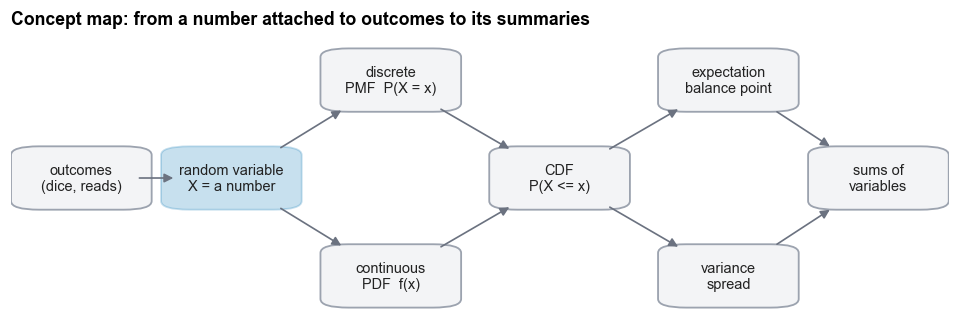

In [2]:
fig = draw_concept_map(); plt.show()

## 먼저 알아 둘 것: 기호 사전

| 기호 | 소리 내어 읽기 | 뜻 |
|---|---|---|
| $X$ (대문자) | "확률 변수 X" | 결과에 따라 값이 달라지는 숫자 (아직 정해지지 않은 값) |
| $x$ (소문자) | "값 x" | X 가 가질 수 있는 특정한 숫자 하나 |
| $P(X = x)$ | "X 가 x 일 확률" | 이산 변수의 PMF |
| $f(x)$ | "x 에서의 밀도" | 연속 변수의 PDF. 확률이 아니라 "확률이 얼마나 빽빽한가" |
| $F(x) = P(X \le x)$ | "X 가 x 이하일 확률" | CDF |
| $\int_a^b f(x)\,dx$ | "a 에서 b 까지 f 를 적분" | 곡선 아래 a~b 구간의 넓이 |
| $E[X]$ | "X 의 기대값" | 오래 반복했을 때의 평균, 분포의 무게중심 |
| $\mathrm{Var}(X)$ | "X 의 분산" | 평균에서 떨어진 거리의 제곱을 평균한 값 |

## 1. 확률 변수: 결과에 숫자를 붙이는 규칙

**한 줄 정의**: 확률 변수 X 는 "각 결과에 숫자 하나를 붙이는 규칙"입니다. 결과가 무작위라서 그 숫자도 무작위입니다 [2].

**왜 필요한가**: 주사위 쌍 (2,5) 자체로는 평균을 낼 수 없습니다. "합" 같은 숫자를 붙여야 평균·분산·비교가 가능해집니다.

**숫자로 따라가기**: X = 두 주사위 눈의 합. 36 칸마다 숫자가 하나씩 붙고, 7 이 붙은 칸은 6 개라 $P(X = 7) = 6/36$ 입니다.
이렇게 "각 값의 확률"을 모두 적은 것이 **PMF**(probability mass function, 확률 질량 함수)입니다.

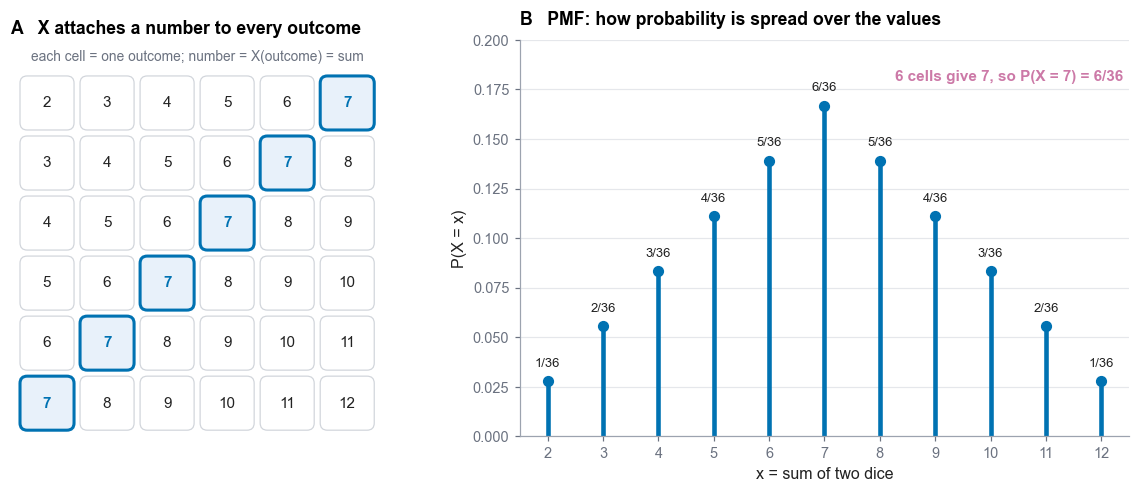

In [3]:
fig = draw_rv_mapping(); plt.show()
vals, cnt = dice_sum_pmf()
assert cnt.sum() == 36 and cnt[vals == 7][0] == 6

**그림에서 볼 것**
- A: 36 칸 각각에 합이 적혀 있습니다. 파란 테두리 6 칸이 X = 7 입니다.
- B: 같은 값이 붙은 칸 수를 36 으로 나눠 세운 막대가 PMF 입니다. 막대 높이를 다 더하면 1 입니다.

> **시퀀싱 데이터에서는**: 한 자리의 깊이(그 자리를 덮는 read 수), 그중 alt read 수, 그리고 둘의 비율인 VAF 추정값은 모두 확률 변수입니다.
> 같은 시료를 다시 시퀀싱하면 값이 조금씩 달라지기 때문입니다.

## 2. CDF: "x 이하일 확률"을 계단으로

**한 줄 정의**: CDF(cumulative distribution function, 누적 분포 함수) $F(x) = P(X \le x)$ 는 PMF 를 왼쪽부터 차례로 더해 간 계단입니다 [2].

**왜 필요한가**: "합이 4 이하일 확률" 같은 범위 질문에 바로 답합니다. 이산이든 연속이든 같은 방식으로 쓸 수 있어 분포를 비교할 때(P4 의 ECDF, KS 검정) 기본이 됩니다.

**숫자로 따라가기**: $F(4) = P(2) + P(3) + P(4) = (1 + 2 + 3)/36 = 6/36$.
계단이 7 에서 올라가는 높이는 $F(7) - F(6) = 21/36 - 15/36 = 6/36 = P(X = 7)$ 입니다.

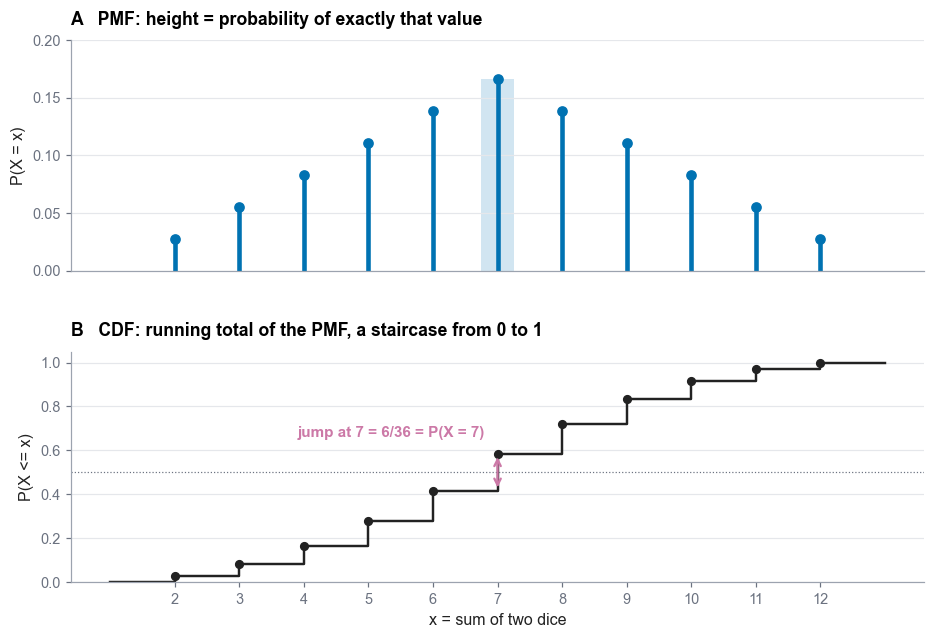

In [4]:
fig, cdf = draw_pmf_cdf(); plt.show()
assert abs(cdf[2] - 6 / 36) < 1e-12 and abs(cdf[5] - cdf[4] - 6 / 36) < 1e-12 and abs(cdf[-1] - 1) < 1e-12

**그림에서 볼 것**
- A 의 막대 높이(옅은 파랑 띠로 강조한 7)가 B 의 계단 높이 차이(자주색 화살표)와 같습니다.
- B 의 계단은 0 에서 시작해 1 에서 끝나고, 절대 내려가지 않습니다. 가는 점선(0.5)을 처음 넘는 곳이 중앙값 7 입니다.

## 3. 연속 변수와 PDF: 히스토그램이 곡선이 될 때

**한 줄 정의**: 연속 변수(키, 깊이 비처럼 값이 이어진 것)는 한 점의 확률이 0 이고, 대신 PDF(probability density function, 확률 밀도 함수) $f(x)$ 아래의 **넓이**가 확률입니다 [2].

**왜 필요한가**: 값이 셀 수 없이 많으면 "정확히 0.31415" 일 확률은 0 입니다. 그래서 "0.3 과 0.4 사이" 처럼 구간의 확률을 넓이로 말합니다.

**숫자로 따라가기**: 표준 정규분포에서 $P(-1 < X < 1) = 0.683$ 입니다. 2 만 개를 뽑으면 약 68% 가 -1 과 1 사이에 있어야 합니다.
히스토그램을 "개수"가 아니라 "비율 ÷ 칸 폭"으로 그리면, 칸을 좁힐수록 PDF 곡선에 붙습니다.

**수식 풀어 읽기**

$$P(a < X < b) = \int_a^b f(x)\,dx$$

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $f(x)$ | "x 에서의 밀도" | 그 근처에 값이 얼마나 빽빽한가 | 검은 곡선의 높이 |
| $\int_a^b \dots dx$ | "a 부터 b 까지 적분" | 아주 좁은 막대(높이 $f(x)$ × 폭 $dx$)를 a~b 에서 다 더한 넓이 | D 의 파란 넓이 |
| $P(a < X < b)$ | "X 가 a 와 b 사이일 확률" | 그 넓이 | 0.683 |

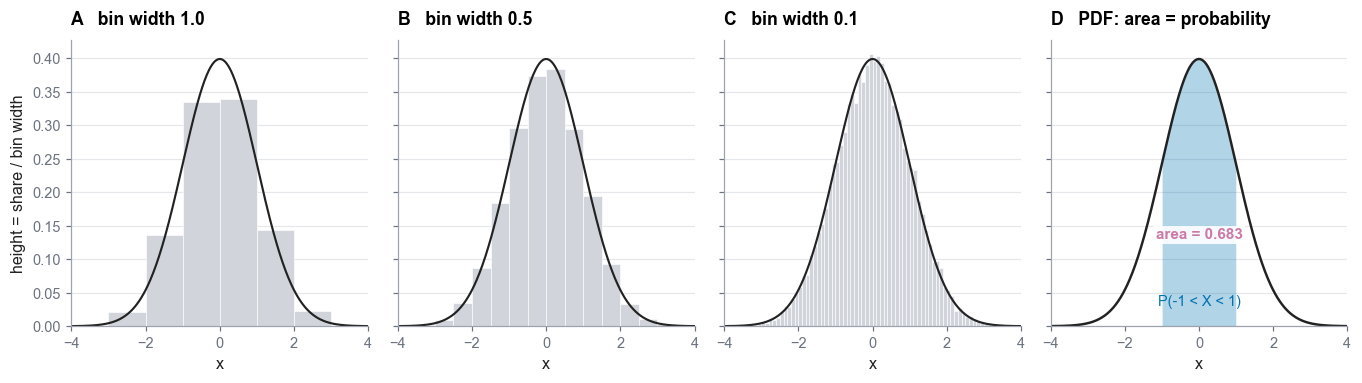

In [5]:
fig, p, frac = draw_hist_to_pdf(); plt.show()
assert abs(p - 0.6827) < 1e-3 and abs(frac - p) < 0.01

**그림에서 볼 것**
- A→C: 칸 폭을 1, 0.5, 0.1 로 좁히면 회색 막대가 검은 곡선(PDF)에 점점 붙습니다. 막대 높이를 "비율 ÷ 칸 폭"으로 맞췄기 때문에 막대 넓이의 합이 늘 1 입니다.
- D: -1 과 1 사이 파란 넓이가 0.683 이고, 2 만 개 중 실제로 그 구간에 든 비율도 같습니다.

### PDF 의 높이는 1 을 넘을 수 있습니다

**한 줄 정의**: PDF 는 확률이 아니라 "단위 길이당 확률"이므로, 좁은 곳에 몰리면 높이가 1 보다 커도 됩니다. 넓이만 1 이면 됩니다 [2].

**숫자로 따라가기**: 0 과 0.5 사이에 고르게 퍼진 분포(Uniform)는 폭 0.5 × 높이 2 = 넓이 1 입니다. 높이가 2 입니다.

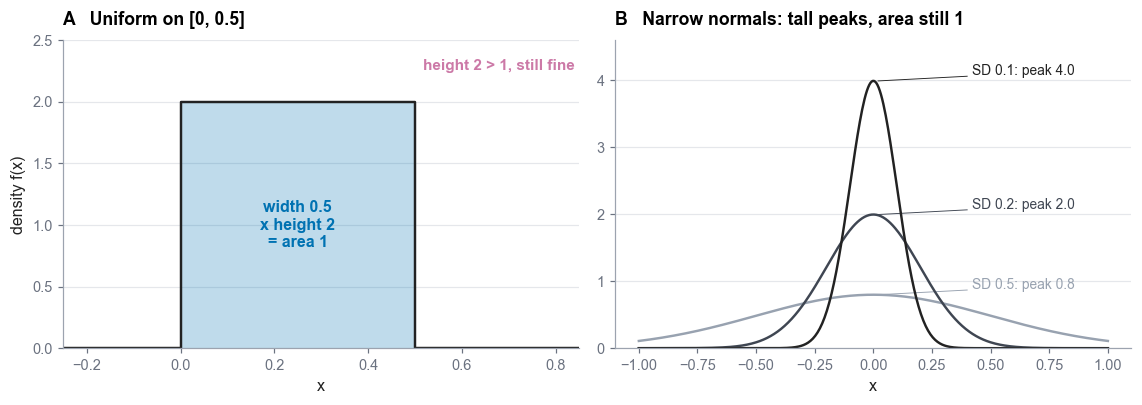

In [6]:
fig = draw_density_above_one(); plt.show()
assert abs(stats.uniform(0, 0.5).pdf(0.2) - 2) < 1e-12 and abs(stats.norm.pdf(0, 0, 0.1) - 3.989) < 1e-3

**그림에서 볼 것**
- A: 높이 2 인 직사각형이지만 넓이는 1 입니다.
- B: 정규분포의 SD(표준편차)를 0.5 → 0.2 → 0.1 로 줄이면 꼭대기가 0.8 → 2.0 → 4.0 으로 높아집니다. 그래도 곡선 아래 넓이는 셋 다 1 입니다.

> **시퀀싱 데이터에서는**: VAF 나 깊이 비의 분포를 그릴 때 세로축이 "밀도"면 값이 1 을 넘는 것이 정상입니다. 세로축이 개수인지, 비율인지, 밀도인지 먼저 확인하세요.

## 4. 기대값: 분포의 무게중심

**한 줄 정의**: 기대값 $E[X]$ 는 값 × 확률을 다 더한 것으로, PMF 막대를 판 위에 올렸을 때 **균형이 맞는 지점**입니다 [2].

**왜 필요한가**: 분포 전체를 숫자 하나로 요약하는 가장 흔한 방법입니다. 하지만 가장 높은 막대(최빈값)나 가운데 값(중앙값)과는 다를 수 있습니다(아래 그림에서 직접 확인).

**숫자로 따라가기** (VAF 0.25 인 자리에서, 첫 alt read 가 나오기 전까지 ref read 가 몇 개 나오나)
- 0 개일 확률 0.25, 1 개 0.75 × 0.25 = 0.1875, 2 개 0.75² × 0.25 = 0.1406, ...
- $E[X] = 0 \times 0.25 + 1 \times 0.1875 + 2 \times 0.1406 + \dots = 3$ 입니다(이 분포는 기하 분포, $E = (1-p)/p$; 아래 셀에서 SciPy `geom` 과 시뮬레이션으로 확인 [3]).
- 가장 흔한 값(최빈값)은 0, 중앙값은 2, 평균은 3 입니다. 오른쪽으로 긴 꼬리가 평균을 끌어당깁니다.

**수식 풀어 읽기**

$$E[X] = \sum_x x \cdot P(X = x)$$

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $x$ | "값" | 가로축 위치 | 막대의 위치 |
| $P(X = x)$ | "그 값의 확률" | 막대의 무게 | 막대 높이 |
| $\sum_x x \cdot P(X = x)$ | "위치 × 무게를 다 더함" | 무게중심 | 자주색 받침점 |

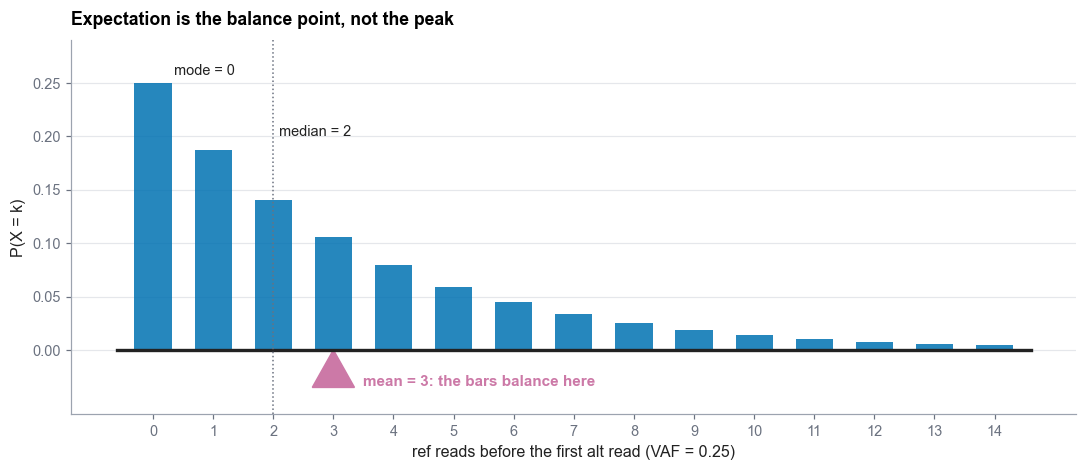

식: 3.0   시뮬레이션 평균: 2.999   중앙값: 2.0


In [7]:
fig, mean, approx = draw_balance(); plt.show()
draws = np.random.default_rng(7).geometric(0.25, 200_000) - 1
assert abs(mean - 3) < 1e-12 and abs(approx - 3) < 0.1 and abs(draws.mean() - 3) < 0.05
print("식:", mean, "  시뮬레이션 평균:", round(draws.mean(), 3), "  중앙값:", np.median(draws))

**그림에서 볼 것**
- 가장 높은 막대는 0 인데, 자주색 받침점(평균 3)은 오른쪽에 있습니다. 긴 오른쪽 꼬리의 막대들이 멀리서 판을 누르기 때문입니다.
- 점선(중앙값 2)은 "왼쪽 넓이와 오른쪽 넓이가 반반"인 곳이라 평균과 또 다릅니다.

## 5. 분산과 표준편차: 평균에서 얼마나 퍼졌나

**한 줄 정의**: 분산 $\mathrm{Var}(X) = E[(X - \mu)^2]$ 는 "평균에서 떨어진 거리의 제곱"의 평균이고, 표준편차(SD)는 그 제곱근이라 원래 단위로 돌아옵니다 [2].

**왜 필요한가**: 평균이 같아도 퍼짐이 다르면 전혀 다른 분포입니다(아래 그림 A). 평균만 비교하면 이 차이를 놓칩니다.

**숫자로 따라가기** (공정한 주사위, 평균 3.5)

| 눈 x | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| 거리 x − 3.5 | −2.5 | −1.5 | −0.5 | +0.5 | +1.5 | +2.5 |
| 거리² | 6.25 | 2.25 | 0.25 | 0.25 | 2.25 | 6.25 |

거리² 의 평균은 $17.5 / 6 = 2.92$, SD 는 $\sqrt{2.92} = 1.71$ 입니다. 제곱하는 이유는 양쪽 거리가 서로 지워지지 않게 하려는 것입니다(거리 자체의 평균은 늘 0).

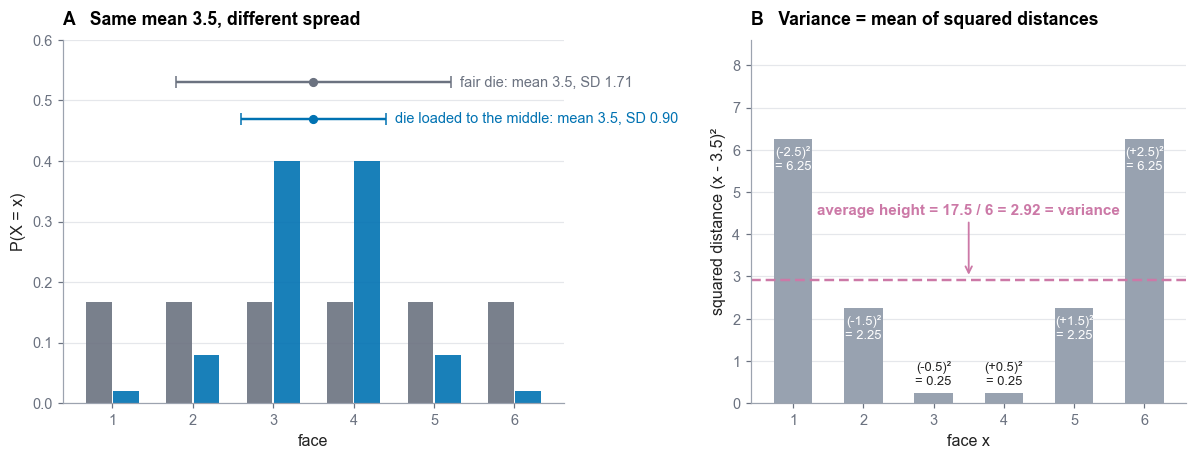

In [8]:
fig = draw_variance(); plt.show()
x = np.arange(1, 7)
assert abs(((x - 3.5) ** 2).mean() - 35 / 12) < 1e-12 and abs(np.random.default_rng(8).integers(1, 7, 200_000).var() - 35 / 12) < 0.03

**그림에서 볼 것**
- A: 두 분포 모두 평균 3.5(점)인데, 가로 막대(± 1 SD)의 길이가 다릅니다. 가운데로 몰린 주사위가 훨씬 좁습니다.
- B: 막대 높이가 각 눈과 평균 3.5 사이 거리의 제곱입니다. 여섯 막대 높이의 평균(자주색 점선, 2.92)이 분산입니다. 멀리 떨어진 1 과 6 의 막대 두 개(6.25 + 6.25 = 12.5)가 합 17.5 의 약 70% 를 차지합니다.

## 6. 변수를 더하면: 기대값은 늘 더해지고, 분산은 공분산이 0 일 때 더해진다

**한 줄 정의**: $E[X + Y] = E[X] + E[Y]$ 는 X 와 Y 가 어떤 관계든 늘 성립합니다(기대값의 선형성). 분산은 $\mathrm{Var}(X + Y) = \mathrm{Var}(X) + \mathrm{Var}(Y) + 2\,\mathrm{Cov}(X, Y)$ 라서, 공분산이 0 일 때 그냥 더해집니다. 독립이면 공분산은 늘 0 이지만, 공분산이 0 이라고 늘 독립인 것은 아닙니다(아래 반례) [2].

**왜 필요한가**: read 하나하나의 결과를 더해 alt read 수를 만들 때, 평균은 쉽게 구해지지만 퍼짐은 read 끼리 서로 얽혀 있는지(공분산)에 달려 있습니다.

**숫자로 따라가기**
- 서로 다른 주사위 두 개의 합: 평균 3.5 + 3.5 = 7, 분산 2.92 + 2.92 = 5.83
- 같은 주사위를 두 번 센 합(X + X = 2X): 평균은 똑같이 7, 분산은 $2^2 \times 2.92 = 11.67$ (두 배)

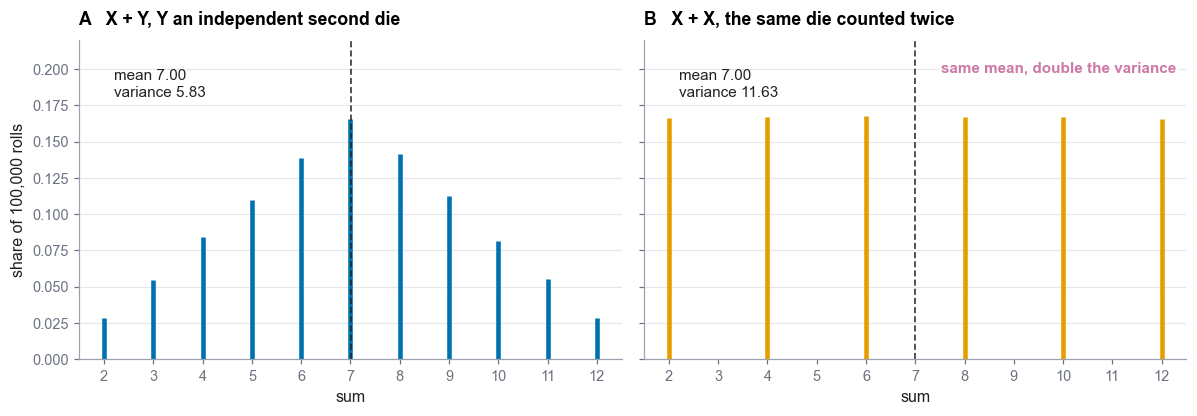

In [9]:
fig, (m1, v1, m2, v2) = draw_sum_dependence(); plt.show()
assert abs(m1 - 7) < 0.03 and abs(m2 - 7) < 0.03 and abs(v1 - 35 / 6) < 0.1 and abs(v2 - 35 / 3) < 0.15

**그림에서 볼 것**
- 두 그림 모두 점선(평균)은 7 입니다.
- A(독립)는 7 에 몰린 삼각형, B(같은 주사위 두 번)는 짝수에만 고르게 퍼진 모양이고 분산이 두 배입니다.

> **시퀀싱 데이터에서는**: alt read 수는 read 마다 "alt 면 1, 아니면 0" 인 지시 변수(indicator)의 합입니다.
> 깊이 n, VAF v 면 선형성 덕분에 $E[\text{alt read 수}] = n v$ 입니다. read 들이 독립이면 분산은 $n v (1 - v)$ 이고,
> VAF 추정값(alt/n)의 SD 는 $\sqrt{v(1-v)/n}$ 입니다. 깊이 30, VAF 0.3 이면 ±0.084 입니다. 중복 read 처럼 독립이 깨지면 실제 퍼짐은 이보다 커집니다.

In [10]:
n_depth, v = 30, 0.3
alt = np.random.default_rng(9).binomial(n_depth, v, 200_000)
sd_formula = np.sqrt(v * (1 - v) / n_depth)
print("VAF 추정값 SD  식:", round(sd_formula, 4), "  시뮬레이션:", round((alt / n_depth).std(), 4))
assert abs((alt / n_depth).std() - sd_formula) < 0.002 and abs(alt.mean() - n_depth * v) < 0.05

VAF 추정값 SD  식: 0.0837   시뮬레이션: 0.0837


**공분산 0 이지만 독립이 아닌 예**: $X \sim N(0, 1)$, $Y = X^2 - 1$. Y 는 X 로 완전히 정해지니 독립이 아닙니다. 그런데 $\mathrm{Cov}(X, Y) = E[X^3] - E[X]E[X^2 - 1] = 0$ 이라,
$\mathrm{Var}(X + Y) = \mathrm{Var}(X) + \mathrm{Var}(Y) = 1 + 2 = 3$ 이 그대로 성립합니다. 분산을 더해도 되는 조건은 "독립"이 아니라 "공분산 0" 입니다.

In [11]:
xn = np.random.default_rng(11).normal(0, 1, 400_000); yn = xn ** 2 - 1
print("Cov(X, Y) =", round(np.cov(xn, yn)[0, 1], 3), "  Var(X + Y) =", round((xn + yn).var(), 3), "(식: 1 + 2 = 3)")
assert abs(np.cov(xn, yn)[0, 1]) < 0.02 and abs((xn + yn).var() - 3) < 0.05

Cov(X, Y) = 0.003   Var(X + Y) = 2.988 (식: 1 + 2 = 3)


## 7. 많이 더하면 종 모양이 나온다 (미리 보기)

**한 줄 정의**: 같은 분포를 따르고 평균과 분산이 있는(유한한) 독립 변수를 여러 개 더하면, 원래 모양과 상관없이 합의 분포가 종 모양(정규분포)에 가까워집니다. 이것이 중심극한정리이고 P3 에서 자세히 봅니다 [5].

**숫자로 따라가기**: 주사위 k 개의 합은 평균 $3.5k$, 분산 $2.92k$ 입니다(6 절). k = 20 이면 평균 70, SD 7.6 입니다.

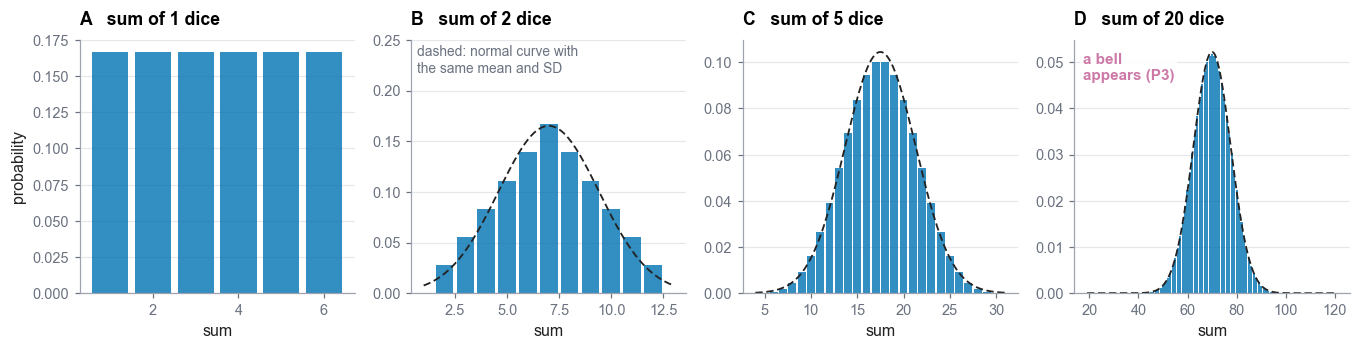

In [12]:
fig = draw_many_dice(); plt.show()

**그림에서 볼 것**
- A: 주사위 하나는 평평합니다. B: 둘이면 삼각형. C, D: 5 개, 20 개면 점선(같은 평균·SD 의 정규 곡선)과 거의 겹칩니다.

**직접 바꿔 보기**: 아래 셀의 `faces` 를 한쪽으로 치우친 주사위로 바꿔도 많이 더하면 종 모양이 되는지 보세요.

In [13]:
faces = np.array([0.5, 0.1, 0.1, 0.1, 0.1, 0.1])     # 1 이 절반 나오는 주사위
p = faces.copy()
for _ in range(29):
    p = np.convolve(p, faces)
print("30 개 합의 평균:", round((np.arange(30, 181) * p).sum(), 2), " (식: 30 × 개별 평균 =", round(30 * (np.arange(1, 7) * faces).sum(), 2), ")")

30 개 합의 평균: 75.0  (식: 30 × 개별 평균 = 75.0 )


## 연습 문제

1. 주사위 두 개의 합 X 에 대해 $P(X \le 9)$ 는? CDF 를 쓰세요.
2. 0 과 0.25 사이에 고르게 퍼진 분포의 PDF 높이는?
3. 깊이 100, VAF 0.5 인 자리에서 VAF 추정값의 SD 는? 깊이를 4 배로 늘리면 SD 는 몇 배가 되나요?
4. X 의 평균이 2, 분산이 3 일 때 $3X + 1$ 의 평균과 분산은?

<details><summary>정답 보기</summary>

1. $F(9) = 30/36 = 0.833$ (9 보다 큰 10, 11, 12 가 3 + 2 + 1 = 6 칸).
2. 넓이가 1 이어야 하므로 $1 / 0.25 = 4$.
3. $\sqrt{0.5 \times 0.5 / 100} = 0.05$. 깊이 4 배면 $\sqrt{4} = 2$ 로 나뉘어 **절반**(0.025)이 됩니다.
4. 평균 $3 \times 2 + 1 = 7$, 분산 $3^2 \times 3 = 27$ (더한 상수 1 은 퍼짐을 바꾸지 않습니다).

</details>

In [14]:
vals, cnt = dice_sum_pmf()
assert abs(cnt[vals <= 9].sum() / 36 - 30 / 36) < 1e-12
assert abs(stats.uniform(0, 0.25).pdf(0.1) - 4) < 1e-12
assert abs(np.sqrt(0.25 / 100) - 0.05) < 1e-12 and abs(np.sqrt(0.25 / 400) - 0.025) < 1e-12
z = np.random.default_rng(10).normal(2, np.sqrt(3), 400_000) * 3 + 1
assert abs(z.mean() - 7) < 0.05 and abs(z.var() - 27) < 0.3

## 정리

- 확률 변수는 결과에 숫자를 붙이는 규칙입니다. 깊이, alt read 수, VAF 추정값이 모두 확률 변수입니다.
- 이산 변수는 PMF(값마다 확률, 막대 높이), 연속 변수는 PDF(곡선 아래 넓이가 확률)로 그립니다. PDF 높이는 1 을 넘을 수 있습니다.
- CDF 는 "x 이하일 확률"의 계단(또는 곡선)이고, 계단의 높이 차이가 PMF 입니다.
- 기대값은 무게중심이고, 꼬리가 길면 최빈값·중앙값과 멀어집니다.
- 분산은 거리 제곱의 평균, SD 는 그 제곱근입니다.
- 기대값은 늘 더해지고, 분산은 공분산이 0 일 때 더해집니다(독립이면 늘 0). 독립이고 분산이 유한한 것을 많이 더하면 종 모양이 됩니다(P3).

## 출처

1. Harvard Statistics 110: Probability (Joe Blitzstein) 강의 영상, YouTube 재생목록. https://www.youtube.com/playlist?list=PL2SOU6wwxB0uwwH80KTQ6ht66KWxbzTIo
   — 머리말의 강의 번호와 제목(Lecture 7–10, 12, 13, 21). 영상 제목으로 확인했습니다.
2. Blitzstein JK, Hwang J. *Introduction to Probability*, 2nd ed. Chapman & Hall/CRC, 2019. 목차: https://www.routledge.com/Introduction-to-Probability-Second-Edition/Blitzstein-Hwang/p/book/9781138369917
   — **목차 기준(본문 미확인)**. 3장(Random variables, PMF, CDF), 4장(Expectation, Linearity, Indicator rvs, Variance, Geometric and Negative Binomial), 5장(Probability density functions, Uniform, Normal), 6장(Summaries of a distribution), 7장(Covariance and correlation)에 이 노트북의 주제가 있다는 것만 확인했습니다. 본문의 정의·정리는 확인하지 못했고, [2] 가 붙은 정의의 계산은 모두 노트북 안에서 시뮬레이션·SciPy 로 따로 확인합니다.
3. SciPy 1.11.4 문서 — 노트북의 계산에 쓴 함수:
   `geom` https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.stats.geom.html ,
   `norm` https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.stats.norm.html ,
   `uniform` https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.stats.uniform.html
4. 이 노트북의 시뮬레이션 결과 — 모든 시뮬레이션 값(2 만~40 만 번), 6 절의 공분산 0 반례.
5. Grinstead CM, Snell JL. *Introduction to Probability*, 2nd ed. American Mathematical Society, 2003 (저자 공개판 2006, GNU FDL). https://math.dartmouth.edu/~prob/prob/prob.pdf
   — 9장 Theorem 9.4(이산), 9.6(연속) Central Limit Theorem: "the sum of n ... independent random variables with common distribution having expected value μ and variance σ²". PDF 본문에서 확인했습니다.